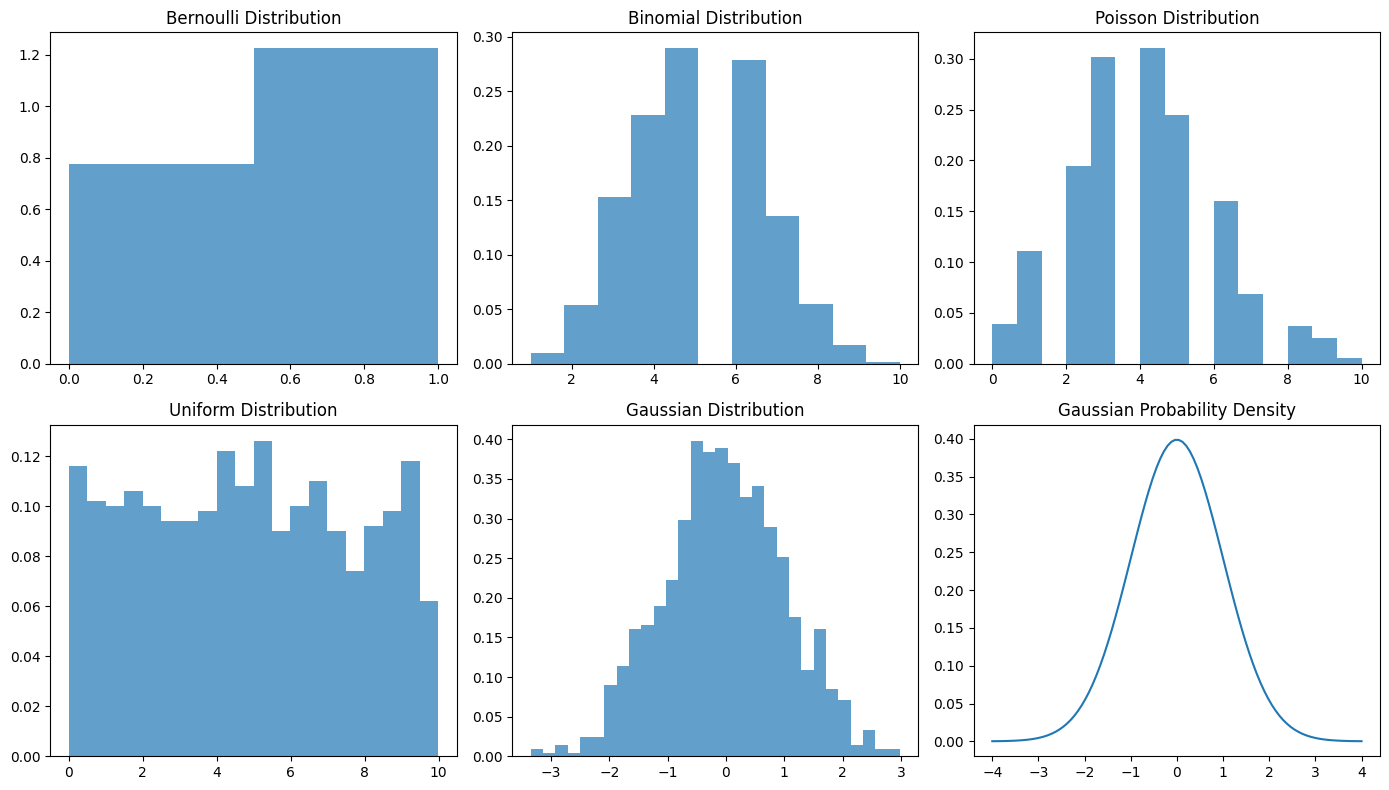

Bayes' Theorem
Probability of Disease given Positive Test: 8.76 %
Simulated Posterior Probability: 8.5 %


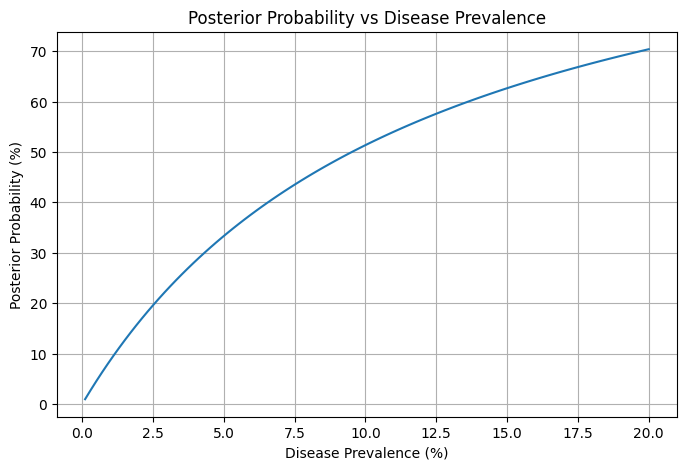

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

np.random.seed(42)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Bernoulli distribution
x = bernoulli.rvs(0.6, size=1000)
axes[0, 0].hist(x, bins=2, density=True, alpha=0.7)
axes[0, 0].set_title("Bernoulli Distribution")

# Binomial distribution
x = binom.rvs(n=10, p=0.5, size=1000)
axes[0, 1].hist(x, bins=11, density=True, alpha=0.7)
axes[0, 1].set_title("Binomial Distribution")

# Poisson distribution
x = poisson.rvs(mu=4, size=1000)
axes[0, 2].hist(x, bins=15, density=True, alpha=0.7)
axes[0, 2].set_title("Poisson Distribution")

# Uniform distribution
x = uniform.rvs(loc=0, scale=10, size=1000)
axes[1, 0].hist(x, bins=20, density=True, alpha=0.7)
axes[1, 0].set_title("Uniform Distribution")

# Gaussian distribution
x = norm.rvs(loc=0, scale=1, size=1000)
axes[1, 1].hist(x, bins=30, density=True, alpha=0.7)
axes[1, 1].set_title("Gaussian Distribution")

# Gaussian PDF
x = np.linspace(-4, 4, 100)
axes[1, 2].plot(x, norm.pdf(x))
axes[1, 2].set_title("Gaussian Probability Density")

plt.tight_layout()
plt.show()

# Bayes' Theorem
prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

false_positive = 1 - specificity

posterior = (
    sensitivity * prevalence
) / (
    sensitivity * prevalence +
    false_positive * (1 - prevalence)
)

print("Bayes' Theorem")
print("Probability of Disease given Positive Test:",
      round(posterior * 100, 2), "%")

# Simulation of 100,000 patients
n = 100000
disease = np.random.binomial(1, prevalence, n)

test_positive = np.where(
    disease == 1,
    np.random.binomial(1, sensitivity, n),
    np.random.binomial(1, false_positive, n)
)

simulated_probability = disease[test_positive == 1].mean()

print("Simulated Posterior Probability:",
      round(simulated_probability * 100, 2), "%")

# Posterior probability for different prevalence values
prevalences = np.linspace(0.001, 0.20, 100)

posteriors = (
    sensitivity * prevalences
) / (
    sensitivity * prevalences +
    false_positive * (1 - prevalences)
)

plt.figure(figsize=(8, 5))
plt.plot(prevalences * 100, posteriors * 100)
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Posterior Probability (%)")
plt.title("Posterior Probability vs Disease Prevalence")
plt.grid()
plt.show()
